Mission 1 — Reconnaissance

| Data Needed | HTML Tag / Class Found | Your Notes |
|---|---|---|
| Book Title | `<a>` inside `<h3>`, full title in the `title` attribute | The visible text is cut off, so the full title is only in `title="..."` |
| Price | `<p class="price_color">` | Shows £54.23, so the "£" must be removed to make it a number |
| Rating | `<p class="star-rating Five">` | The rating is a word, not a number |
| Availability | `<p class="instock availability">` | The text "In stock" has spaces, so it needs trimming |

Mission 2 — Capture the Data

In [2]:
import requests
from bs4 import BeautifulSoup
import pandas as pd



In [3]:
url = "https://books.toscrape.com/"
response = requests.get(url)
response.encoding = "utf-8"

print(response.status_code)

200


In [4]:
soup = BeautifulSoup(response.text, "html.parser")

cards = soup.find_all("article", class_="product_pod")
print(len(cards))

20


In [6]:
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

books = []

for card in cards:
    title = card.h3.a["title"]
    price = float(card.find("p", class_="price_color").text.replace("£", ""))
    rating_word = card.find("p", class_="star-rating")["class"][1]
    rating = rating_map[rating_word]
    availability = card.find("p", class_="instock availability").text.strip()

    books.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

df = pd.DataFrame(books)
print(df.shape)
df.head()

(20, 4)


,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


Mission 3 — Scale the Operation

In [7]:
rating_map = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}

def scrape_page(url):
    response = requests.get(url)
    response.encoding = "utf-8"
    soup = BeautifulSoup(response.text, "html.parser")
    cards = soup.find_all("article", class_="product_pod")

    page_books = []
    for card in cards:
        title = card.h3.a["title"]
        price = float(card.find("p", class_="price_color").text.replace("£", ""))
        rating = rating_map[card.find("p", class_="star-rating")["class"][1]]
        availability = card.find("p", class_="instock availability").text.strip()

        page_books.append({
            "Title": title,
            "Price": price,
            "Rating": rating,
            "Availability": availability
        })
    return page_books

In [8]:
all_books = []

for page in range(1, 4):
    url = f"https://books.toscrape.com/catalogue/page-{page}.html"
    page_books = scrape_page(url)
    all_books.extend(page_books)
    print(f"Page {page}: {len(page_books)} books")

df = pd.DataFrame(all_books)
print(df.shape)
df.head()

Page 1: 20 books
Page 2: 20 books
Page 3: 20 books
(60, 4)


,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [9]:
print(df.dtypes)
print(df.isna().sum())
df.head()

Title            object
Price           float64
Rating            int64
Availability     object
dtype: object
Title           0
Price           0
Rating          0
Availability    0
dtype: int64


,Title,Price,Rating,Availability
0,A Light in the Attic,51.77,3,In stock
1,Tipping the Velvet,53.74,1,In stock
2,Soumission,50.10,1,In stock
3,Sharp Objects,47.82,4,In stock
4,Sapiens: A Brief History of Humankind,54.23,5,In stock


In [10]:
df.to_csv("competitor_books.csv", index=False)
print("Saved!", len(df), "rows")

from google.colab import files
files.download("competitor_books.csv")

Saved! 60 rows


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Mission 4 — Intelligence Analysis

In [12]:
# Q1. Most expensive book
print("Q1: Most expensive book:")
display(df[df["Price"] == df["Price"].max()])

# Q2. Cheapest book
print("Q2: Cheapest book:")
display(df[df["Price"] == df["Price"].min()])

# Q3. Average price
print("Q3: Average price: £", round(df["Price"].mean(), 2))

# Q4. Number of 5-star books
print("Q4: Number of 5-star books:", (df["Rating"] == 5).sum())

# Q5. Percentage of books in stock
in_stock_pct = (df["Availability"] == "In stock").mean() * 100
print("Q5: Percentage in stock:", round(in_stock_pct, 1), "%")

# Q6. Top 5 highest-rated books (ties broken by lowest price)
print("Q6: Top 5 highest-rated books:")
display(df.sort_values(["Rating", "Price"], ascending=[False, True]).head(5))

# Q7. Cheapest 5-star book
five_star = df[df["Rating"] == 5]
print("Q7: Cheapest 5-star book:")
display(five_star[five_star["Price"] == five_star["Price"].min()])

Q1: Most expensive book:


,Title,Price,Rating,Availability
40,Slow States of Collapse: Poems,57.31,3,In stock


Q2: Cheapest book:


,Title,Price,Rating,Availability
20,In Her Wake,12.84,1,In stock


Q3: Average price: £ 35.0
Q4: Number of 5-star books: 14
Q5: Percentage in stock: 100.0 %
Q6: Top 5 highest-rated books:


,Title,Price,Rating,Availability
34,Sophie's World,15.94,5,In stock
54,Thirst,17.27,5,In stock
12,Set Me Free,17.46,5,In stock
30,The Four Agreements: A Practical Guide to Pers...,17.66,5,In stock
43,#HigherSelfie: Wake Up Your Life. Free Your So...,23.11,5,In stock


Q7: Cheapest 5-star book:


,Title,Price,Rating,Availability
34,Sophie's World,15.94,5,In stock


Business Decision

In [13]:
overall_avg = df["Price"].mean()
five_star = df[df["Rating"] == 5]

# Evidence 1: average price of 5-star books vs all books
print("Average price, all books: £", round(overall_avg, 2))
print("Average price, 5-star books: £", round(five_star["Price"].mean(), 2))

# Evidence 2: average price and number of books for each rating
print("\nPrice and count by rating:")
print(df.groupby("Rating")["Price"].agg(["count", "mean"]).round(2))

# Evidence 3: high-rated books priced below average
value_picks = df[(df["Rating"] >= 4) & (df["Price"] < overall_avg)]
print("\nBooks rated 4 or 5 AND priced below average:", len(value_picks), "out of", len(df))

# Evidence 4: do higher prices mean higher ratings?
print("Correlation between price and rating:", round(df["Price"].corr(df["Rating"]), 3))

display(value_picks.sort_values(["Rating", "Price"], ascending=[False, True]))

Average price, all books: £ 35.0
Average price, 5-star books: £ 32.48

Price and count by rating:
        count   mean
Rating              
1          15  34.31
2           8  33.87
3          13  38.81
4          10  35.53
5          14  32.48

Books rated 4 or 5 AND priced below average: 13 out of 60
Correlation between price and rating: -0.027


,Title,Price,Rating,Availability
34,Sophie's World,15.94,5,In stock
54,Thirst,17.27,5,In stock
12,Set Me Free,17.46,5,In stock
30,The Four Agreements: A Practical Guide to Pers...,17.66,5,In stock
43,#HigherSelfie: Wake Up Your Life. Free Your So...,23.11,5,In stock
32,The Elephant Tree,23.82,5,In stock
23,Chase Me (Paris Nights #2),25.27,5,In stock
24,Black Dust,34.53,5,In stock
47,Untitled Collection: Sabbath Poems 2014,14.27,4,In stock
53,This One Summer,19.49,4,In stock


Recommendation: I would prioritize books rated 4 or 5 stars and priced below the £35.00 average, starting with the 8 five-star titles in that group, such as Sophie's World (£15.94), Thirst (£17.27) and Set Me Free (£17.46). The data supports this: 5-star books average £32.48, which is below the overall average of £35.00, and the correlation between price and rating is almost zero (-0.027), so high quality does not require a high price. In total, 13 of the 60 scraped books (21.7%) are both highly rated and cheaper than average, and all of them are in stock.

Final Challenge - The CEO Has £100



In [14]:
import numpy as np

def best_basket(data, budget=100):
    prices = (data["Price"] * 100).round().astype(int).to_numpy()   # prices in pence
    ratings = data["Rating"].to_numpy()
    cap = int(budget * 100)
    n = len(data)

    best = np.zeros(cap + 1, dtype=int)         # best total rating for each spending limit
    chosen = np.zeros((n, cap + 1), dtype=bool)

    for i in range(n):
        p, r = prices[i], ratings[i]
        new_best = best.copy()
        new_best[p:] = np.maximum(best[p:], best[:cap + 1 - p] + r)
        chosen[i] = new_best > best
        best = new_best

    # find the cheapest spend that reaches the best score, then trace back the books
    c = int(np.argmax(best == best[cap]))
    picks = []
    for i in range(n - 1, -1, -1):
        if chosen[i, c]:
            picks.append(i)
            c -= prices[i]
    return data.iloc[sorted(picks)]

basket = best_basket(df, 100).reset_index(drop=True)
display(basket)

print("Books selected:", len(basket))
print("Total cost: £", round(basket["Price"].sum(), 2))
print("Total rating:", basket["Rating"].sum())

,Title,Price,Rating,Availability
0,"Starving Hearts (Triangular Trade Trilogy, #1)",13.99,2,In stock
1,Set Me Free,17.46,5,In stock
2,The Four Agreements: A Practical Guide to Pers...,17.66,5,In stock
3,Sophie's World,15.94,5,In stock
4,Untitled Collection: Sabbath Poems 2014,14.27,4,In stock
5,Thirst,17.27,5,In stock


Books selected: 6
Total cost: £ 96.59
Total rating: 26


| Book | Price (£) | Rating |
|---|---|---|
| Starving Hearts (Triangular Trade Trilogy, #1) | 13.99 | 2 |
| Set Me Free | 17.46 | 5 |
| The Four Agreements: A Practical Guide to Personal Freedom | 17.66 | 5 |
| Sophie's World | 15.94 | 5 |
| Untitled Collection: Sabbath Poems 2014 | 14.27 | 4 |
| Thirst | 17.27 | 5 |

**Books selected:** 6
**Total cost:** £96.59
**Total rating score:** 26 stars

Bonus Question 3 and 4

Rating
1    15
2     8
3    13
4    10
5    14
Name: count, dtype: int64


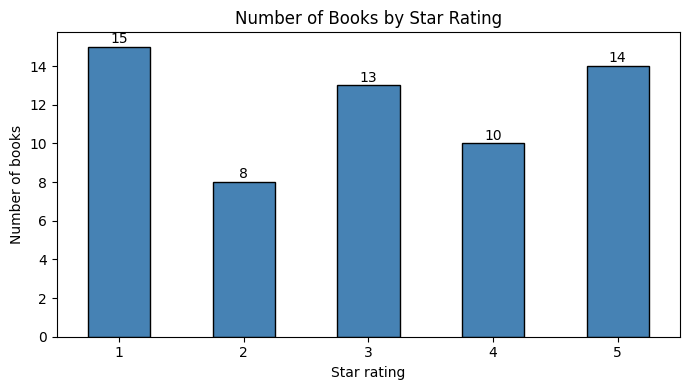

In [15]:
import matplotlib.pyplot as plt

rating_counts = df["Rating"].value_counts().sort_index()
print(rating_counts)

ax = rating_counts.plot(kind="bar", color="steelblue", edgecolor="black", figsize=(7, 4))
ax.set_title("Number of Books by Star Rating")
ax.set_xlabel("Star rating")
ax.set_ylabel("Number of books")
plt.xticks(rotation=0)

for i, v in enumerate(rating_counts):
    ax.text(i, v + 0.2, str(v), ha="center")

plt.tight_layout()
plt.show()